# Pertemuan 7 — Tugas: Perbandingan Exact NN, Annoy, HNSW, dan FAISS

Tugas ini membandingkan pencarian tetangga terdekat secara exact dengan tiga pustaka ANN, yaitu Annoy, HNSW, dan FAISS. Dataset yang dipakai berupa 10.000 vektor acak berdimensi 128 yang dinormalisasi dengan `StandardScaler`.

Tujuan pengukuran adalah melihat selisih waktu komputasi antara pencarian exact yang menghitung jarak ke seluruh data dan pencarian approximate yang memanfaatkan struktur index. Modul meminta percobaan dijalankan pada Google Colab dan pada aplikasi PyDroid3 di Android, lalu hasilnya dibandingkan. Pengukuran pada laporan ini dilakukan pada perangkat komputer yang dipakai menyusun laporan, dan perbandingan dengan perangkat lain dibahas pada bagian analisis.

Sumber: [Tugas](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/tugas).

In [1]:
%matplotlib inline

import platform
import time

import faiss
import hnswlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

## 1. Spesifikasi perangkat

Sel berikut mencatat spesifikasi perangkat yang dipakai pada pengukuran agar hasilnya dapat dibandingkan dengan perangkat lain.

In [2]:
print("Sistem operasi :", platform.platform())
print("Prosesor       :", platform.processor())
print("Python         :", platform.python_version())

Sistem operasi : macOS-27.0-arm64-arm-64bit-Mach-O
Prosesor       : arm
Python         : 3.14.7


## 2. Menyiapkan dataset

Dataset dibentuk dari 10.000 vektor acak berdimensi 128, kemudian dinormalisasi agar setiap dimensi berada pada skala yang sebanding.

In [3]:
# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

## 3. Exact Nearest Neighbor

Pencarian exact dilakukan dengan `NearestNeighbors` bermetode *brute force* dengan seluruh inti prosesor dimanfaatkan.

In [4]:
# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean', n_jobs=-1)
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

Exact NN done in 0.183 s


## 4. Annoy

Index Annoy dibangun dengan 10 pohon, kemudian pencarian dilakukan untuk seluruh vektor dengan `search_k` eksplisit.

In [5]:
# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k, search_k=2_000) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

Annoy done in 1.924 s


## 5. HNSW

HNSW dibangun dengan `M = 16` dan `ef_construction = 200`, kemudian pencarian memakai `ef = 200`.

In [6]:
# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

HNSW done in 1.532 s


## 6. FAISS IVF

FAISS memakai `IndexIVFFlat` dengan 100 klaster dan `nprobe = 10` pada tahap pencarian.

In [7]:
# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

FAISS IVF done in 0.076 s


## 7. Ringkasan waktu

Sel berikut menampilkan ringkasan waktu setiap metode, disertai nilai recall terhadap hasil pencarian exact dan percepatan relatif terhadap pencarian exact.

In [8]:
# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")


def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(np.asarray(I_pred[i])[:k]) & set(np.asarray(I_gt[i])[:k]))
    return correct / (len(I_pred) * k)


tabel = pd.DataFrame([
    {"Metode": "Exact NN", "Waktu (detik)": round(time_exact, 4), "Recall@10": 1.0,
     "Percepatan": 1.0},
    {"Metode": "Annoy", "Waktu (detik)": round(time_annoy, 4),
     "Recall@10": round(recall_at_k(idx_annoy, idx_exact, k), 4),
     "Percepatan": round(time_exact / time_annoy, 2)},
    {"Metode": "HNSW", "Waktu (detik)": round(time_hnsw, 4),
     "Recall@10": round(recall_at_k(idx_hnsw, idx_exact, k), 4),
     "Percepatan": round(time_exact / time_hnsw, 2)},
    {"Metode": "FAISS IVF", "Waktu (detik)": round(time_faiss, 4),
     "Recall@10": round(recall_at_k(idx_faiss, idx_exact, k), 4),
     "Percepatan": round(time_exact / time_faiss, 2)},
])

display(tabel)

=== Ringkasan Waktu (detik) ===
Exact NN : 0.183
Annoy    : 1.924
HNSW     : 1.532
FAISS    : 0.076


,Metode,Waktu (detik),Recall@10,Percepatan
0,Exact NN,0.1834,1.0000,1.00
1,Annoy,1.9236,0.5442,0.10
2,HNSW,1.5320,0.9805,0.12
3,FAISS IVF,0.0756,0.4182,2.43


## 8. Visualisasi perbandingan waktu

Grafik batang berikut memperlihatkan perbandingan waktu komputasi keempat metode. Skala logaritmik dipakai karena selisih waktunya cukup besar.

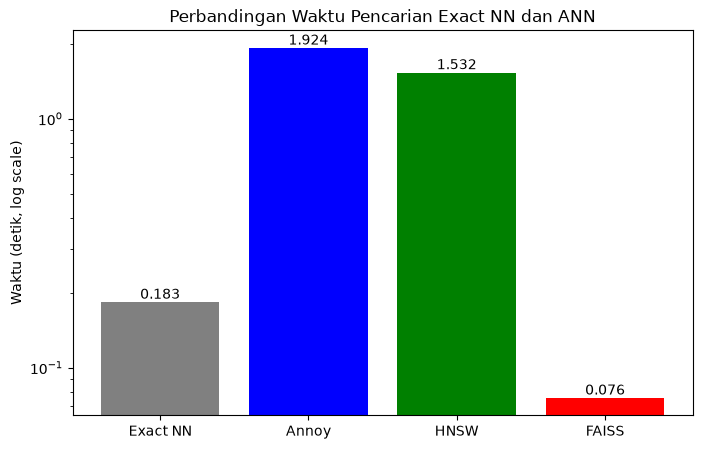

In [9]:
plt.figure(figsize=(8, 5))
metode = ["Exact NN", "Annoy", "HNSW", "FAISS"]
waktu = [time_exact, time_annoy, time_hnsw, time_faiss]
plt.bar(metode, waktu, color=["gray", "blue", "green", "red"])
plt.yscale("log")
plt.ylabel("Waktu (detik, log scale)")
plt.title("Perbandingan Waktu Pencarian Exact NN dan ANN")
for i, v in enumerate(waktu):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.show()

## 9. Analisis

Pada dataset 10.000 vektor berdimensi 128, pencarian exact selesai dalam waktu sekitar 0,18 detik. Waktu tersebut tergolong singkat karena perhitungan jarak dilakukan secara tervektorisasi dengan memanfaatkan seluruh inti prosesor, dan jumlah perhitungannya masih terjangkau pada ukuran data ini. Biaya pencarian exact bertambah secara kuadratik terhadap jumlah data, sehingga kenaikannya baru terasa ketika jumlah data diperbesar.

Hasil pengukuran ANN pada ukuran data ini belum memperlihatkan percepatan. FAISS IVF menjadi yang tercepat dengan waktu di bawah 0,1 detik, sedangkan Annoy dan HNSW masing-masing memerlukan waktu sekitar 1,9 detik dan 1,5 detik, keduanya lebih lama daripada pencarian exact. Penyebabnya adalah biaya tetap yang harus dibayar ANN, yaitu pembuatan index dan pemanggilan pencarian secara berulang dari Python untuk seluruh 10.000 vektor. Pada Annoy, pemanggilan `get_nns_by_vector` dilakukan satu per satu sehingga biaya pemanggilan tersebut mendominasi, sementara pencarian exact memproses seluruh query sekaligus dalam satu operasi matriks. Keunggulan ANN baru terlihat pada data yang jauh lebih besar, sebagaimana ditunjukkan pada Praktikum 4 dan Praktikum 6, di mana pencarian exact memerlukan waktu ratusan detik sedangkan HNSW dan FAISS hanya puluhan hingga ratusan detik.

Nilai recall memperlihatkan kompromi antara akurasi dan kecepatan. HNSW dengan `ef = 200` mencapai recall 0,9805 karena memeriksa banyak kandidat pada graf, sedangkan Annoy dengan `search_k = 2000` memperoleh 0,5442 dan FAISS IVF dengan `nprobe = 10` memperoleh 0,4182. Pada data berdimensi 128 yang acak, tetangga terdekat cenderung tersebar sehingga pencarian approximate lebih mudah kehilangan sebagian tetangga. Recall ketiga metode dapat dinaikkan dengan memperbesar parameter pencariannya, dengan konsekuensi waktu yang bertambah.

Perbandingan antara komputer dan perangkat Android memiliki beberapa hal yang perlu diperhatikan. Perangkat Android memiliki jumlah inti prosesor yang lebih sedikit, kapasitas memori yang lebih kecil, dan tidak menyediakan pustaka aljabar linier yang teroptimasi secepat BLAS pada komputer. Perbedaan ini memengaruhi waktu pembuatan index lebih besar daripada waktu pencarian, karena pembuatan index melibatkan seluruh data. Pada data berdimensi 128, kebutuhan memori juga bertambah karena setiap vektor memerlukan 128 nilai pecahan, sehingga pengukuran pada perangkat dengan memori terbatas umumnya memakai jumlah data atau jumlah dimensi yang lebih kecil. Google Colab menyediakan sumber daya yang lebih besar daripada telepon sehingga hasilnya lebih dekat dengan pengukuran pada komputer, sedangkan PyDroid3 berjalan langsung di perangkat Android sehingga waktu eksekusinya lebih lama dan lebih sensitif terhadap kapasitas memori yang tersedia.

## Kesimpulan

Pencarian exact menghasilkan tetangga terdekat yang paling akurat dan pada dataset 10.000 vektor berdimensi 128 masih menjadi pilihan yang paling cepat karena perhitungannya tervektorisasi. Ketiga pustaka ANN belum memperlihatkan percepatan pada ukuran data tersebut, kecuali FAISS IVF yang tetap lebih cepat, karena biaya pembuatan index dan pemanggilan pencarian per vektor masih mendominasi. Recall tertinggi diperoleh HNSW dengan `ef = 200`, sedangkan Annoy dan FAISS IVF menghasilkan recall yang lebih rendah sesuai nilai parameter pencariannya. Dengan demikian, pemilihan antara pencarian exact dan ANN bergantung pada ukuran data: pada data kecil pencarian exact sudah memadai, sedangkan pada data besar ANN menjadi kebutuhan, dan parameter pencarian menentukan letak kompromi antara akurasi dan kecepatan. Perbedaan waktu antar perangkat terutama dipengaruhi oleh jumlah inti prosesor, kapasitas memori, serta ketersediaan pustaka aljabar linier yang teroptimasi.